DIAMETER =                    0  / TELESCOPE diameter                            [astropy.io.fits.card]


Calculated FWHM: 4.4504 degrees


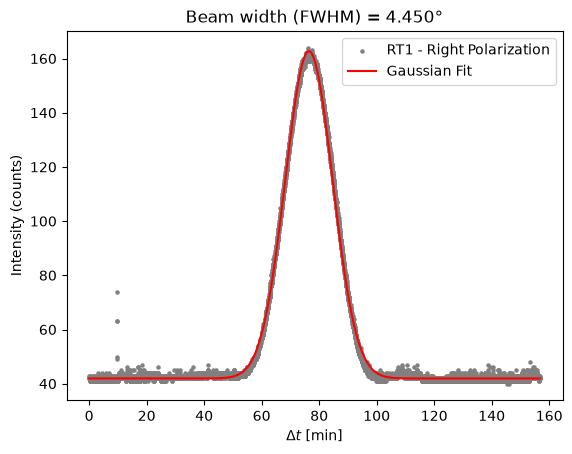

In [1]:
from astropy.io import fits
from astropy.table import Table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

with fits.open('20260622_SUN_VINCENT.fits') as hdul:
    astro_table = Table(hdul[1].data)
    data = astro_table.to_pandas()
#print(data.columns)


# Define the Gaussian with a baseline offset
def gaussian_with_baseline(x, A, x0, sigma, B):
    return A * np.exp(-(x - x0)**2 / (2 * sigma**2)) + B


delta_t_days = data['JD']-data['JD'][0]
delta_t_hours = delta_t_days*24
delta_t_min = delta_t_hours*60
delta_t_sec = delta_t_min*60


x_data = delta_t_min
y_data = data['RIGHT_POL'].values

#initial guesses 
initial_B = np.min(y_data)                      # Baseline noise level
initial_A = np.max(y_data) - initial_B          # Height of the peak above baseline
initial_x0 = x_data[np.argmax(y_data)]         # X-coordinate of the max value
initial_sigma = (np.max(x_data) - np.min(x_data)) / 6  # Rough initial guess for width

guesses = [initial_A, initial_x0, initial_sigma, initial_B]

# Fit the model to telescope data
popt, pcov = curve_fit(gaussian_with_baseline, x_data, y_data, p0=guesses)
A_fit, x0_fit, sigma_fit, B_fit = popt

# Calculate FWHM in minutes
fwhm = 2.35482 * abs(sigma_fit)

# declination of the Sun on 22nd June 2026 in degrees = 23.44
# average speed = 360/(24*60) = 0.25 deg/min
declination_rad = np.radians(23.44)
# drift formula for the sun
fwhm_degrees = fwhm * 0.25 * np.cos(declination_rad)

print(f"Calculated FWHM: {fwhm_degrees:.4f} degrees")

# 5. Plot the result to verify the fit visually
plt.scatter(x_data, y_data, label='RT1 - Right Polarization', color='gray', s=5)
#plt.plot(x_data, gaussian_with_baseline(x_data, *popt), color='red', label=f'Gaussian Fit (FWHM={fwhm_degrees:.3f}°)')
plt.plot(x_data, gaussian_with_baseline(x_data, *popt), color='red', label=f'Gaussian Fit')
plt.xlabel(r'$\Delta t$ [min]')
plt.ylabel('Intensity (counts)')
plt.title('Beam width (FWHM) = %.3f°'%fwhm_degrees)
plt.legend()
plt.show()

Calculated FWHM: 4.4116 degrees


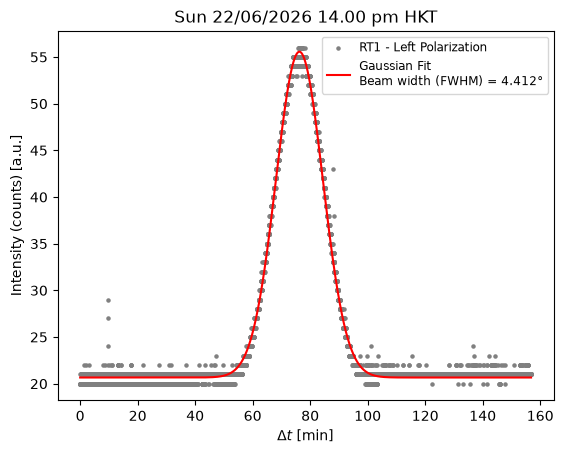

In [2]:
from astropy.io import fits
from astropy.table import Table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

with fits.open('20260622_SUN_VINCENT.fits') as hdul:
    astro_table = Table(hdul[1].data)
    data = astro_table.to_pandas()
#print(data.columns)


# Define the Gaussian with a baseline offset
def gaussian_with_baseline(x, A, x0, sigma, B):
    return A * np.exp(-(x - x0)**2 / (2 * sigma**2)) + B


delta_t_days = data['JD']-data['JD'][0]
delta_t_hours = delta_t_days*24
delta_t_min = delta_t_hours*60
delta_t_sec = delta_t_min*60


x_data = delta_t_min
y_data = data['LEFT_POL'].values

#initial guesses 
initial_B = np.min(y_data)                      # Baseline noise level
initial_A = np.max(y_data) - initial_B          # Height of the peak above baseline
initial_x0 = x_data[np.argmax(y_data)]         # X-coordinate of the max value
initial_sigma = (np.max(x_data) - np.min(x_data)) / 6  # Rough initial guess for width

guesses = [initial_A, initial_x0, initial_sigma, initial_B]

# Fit the model to telescope data
popt, pcov = curve_fit(gaussian_with_baseline, x_data, y_data, p0=guesses)
A_fit, x0_fit, sigma_fit, B_fit = popt

# Calculate FWHM in minutes
fwhm = 2.35482 * abs(sigma_fit)

# declination of the Sun on 22nd June 2026 in degrees = 23.44
# average speed = 360/(24*60) = 0.25 deg/min
declination_rad = np.radians(23.44)
# drift formula for the sun
fwhm_degrees = fwhm * 0.25 * np.cos(declination_rad)

print(f"Calculated FWHM: {fwhm_degrees:.4f} degrees")

# 5. Plot the result to verify the fit visually
plt.scatter(x_data, y_data, label='RT1 - Left Polarization', color='gray', s=5)
#plt.plot(x_data, gaussian_with_baseline(x_data, *popt), color='red', label=f'Gaussian Fit (FWHM={fwhm_degrees:.3f}°)')
plt.plot(x_data, gaussian_with_baseline(x_data, *popt), color='red', label=f'Gaussian Fit \nBeam width (FWHM) = %.3f°'%fwhm_degrees)
plt.xlabel(r'$\Delta t$ [min]')
plt.ylabel('Intensity (counts) [a.u.]')
plt.title('Sun 22/06/2026 14.00 pm HKT')
plt.legend(fontsize='small')
plt.show()

DIAMETER =                    0  / TELESCOPE diameter                            [astropy.io.fits.card]


0.22936928513072966
Calculated FWHM: 4.4504 degrees


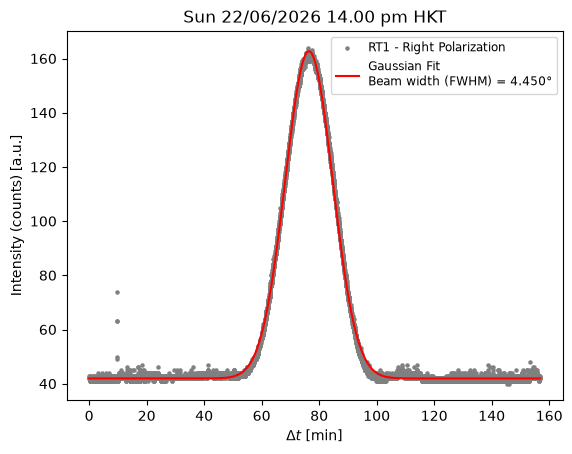

In [1]:
from astropy.io import fits
from astropy.table import Table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

with fits.open('20260622_SUN_VINCENT.fits') as hdul:
    astro_table = Table(hdul[1].data)
    data = astro_table.to_pandas()
#print(data.columns)


# Define the Gaussian with a baseline offset
def gaussian_with_baseline(x, A, x0, sigma, B):
    return A * np.exp(-(x - x0)**2 / (2 * sigma**2)) + B


delta_t_days = data['JD']-data['JD'][0]
delta_t_hours = delta_t_days*24
delta_t_min = delta_t_hours*60
delta_t_sec = delta_t_min*60


x_data = delta_t_min
y_data = data['RIGHT_POL'].values

#initial guesses 
initial_B = np.min(y_data)                      # Baseline noise level
initial_A = np.max(y_data) - initial_B          # Height of the peak above baseline
initial_x0 = x_data[np.argmax(y_data)]         # X-coordinate of the max value
initial_sigma = (np.max(x_data) - np.min(x_data)) / 6  # Rough initial guess for width

guesses = [initial_A, initial_x0, initial_sigma, initial_B]

# Fit the model to telescope data
popt, pcov = curve_fit(gaussian_with_baseline, x_data, y_data, p0=guesses)
A_fit, x0_fit, sigma_fit, B_fit = popt

# Calculate FWHM in minutes
fwhm = 2.35482 * abs(sigma_fit)

# declination of the Sun on 22nd June 2026 in degrees = 23.44
# average speed = 360/(24*60) = 0.25 deg/min
declination_rad = np.radians(23.44)
# drift formula for the sun
fwhm_degrees = fwhm * 0.25 * np.cos(declination_rad)

print(0.25 * np.cos(declination_rad))

print(f"Calculated FWHM: {fwhm_degrees:.4f} degrees")

plt.scatter(x_data, y_data, label='RT1 - Right Polarization', color='gray', s=5)
#plt.plot(x_data, gaussian_with_baseline(x_data, *popt), color='red', label=f'Gaussian Fit (FWHM={fwhm_degrees:.3f}°)')
plt.plot(x_data, gaussian_with_baseline(x_data, *popt), color='red', label=f'Gaussian Fit \nBeam width (FWHM) = %.3f°'%fwhm_degrees)
plt.xlabel(r'$\Delta t$ [min]')
plt.ylabel('Intensity (counts) [a.u.]')
plt.title('Sun 22/06/2026 14.00 pm HKT')
plt.legend(fontsize='small')
plt.show()

In [4]:
k_B = 1.38e-23  # Boltzmann constant [J/K]
dish_diameter = 3.0  # Dish diameter in meters
aperture_eff = 0.60  # Estimated aperture efficiency (60%)
solar_flux_sfu = 125.0  # Observed F10.7 flux on June 22, 2026 [SFU]


# Raw isolated solar peak
delta_P_raw = A_fit
P_floor = B_fit

print(f"--- RAW DATA ANALYSIS ---")
print(f"Calculated Baseline Floor (P_floor): {P_floor:.2f} raw counts")
print(f"Isolated Peak Signal (Delta P_raw): {delta_P_raw:.2f} raw counts")


# ==========================================
# PHYSICAL CALIBRATION (KELVIN)
# ==========================================

# Calculate Effective Aperture
A_geom = np.pi * (dish_diameter / 2) ** 2
A_e = aperture_eff * A_geom

# Convert SFU to W/m^2/Hz
S_flux = solar_flux_sfu * 1e-22

# Expected Antenna Temperature of the Sun
T_sun_expected = (S_flux * A_e) / (2 * k_B)

# Calculate Calibration Factor K
K = T_sun_expected / delta_P_raw

print(f"\n--- CALIBRATION RESULTS ---")
print(f"Expected Solar Antenna Temp (T_sun): {T_sun_expected:.2f} K")
print(f"Calibration Factor (K): {K:.5f} Kelvin / raw count")

--- RAW DATA ANALYSIS ---
Calculated Baseline Floor (P_floor): 41.93 raw counts
Isolated Peak Signal (Delta P_raw): 120.77 raw counts

--- CALIBRATION RESULTS ---
Expected Solar Antenna Temp (T_sun): 1920.81 K
Calibration Factor (K): 15.90429 Kelvin / raw count


In [5]:
# ==========================================
# TRANSFORM DATA TO PHYSICAL UNITS
# ==========================================
# Subtract baseline electronic noise and convert to Kelvin
brightness_temp_kelvin = (y_data - P_floor) * K
fitted_curve_kelvin = (
    gaussian_with_baseline(x_data, *popt) - P_floor
) * K

/tmp/ipykernel_8750/304943827.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize='small')


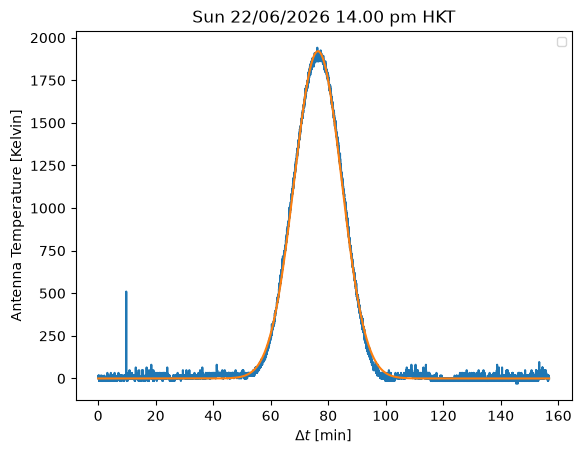

In [6]:
plt.plot(x_data,brightness_temp_kelvin)
plt.plot(x_data,fitted_curve_kelvin)
plt.xlabel(r'$\Delta t$ [min]')
plt.ylabel('Antenna Temperature [Kelvin]')
plt.title('Sun 22/06/2026 14.00 pm HKT')
plt.legend(fontsize='small')
plt.show()